# CNN-Based Image Classification Using Intel Image Dataset

## 1. Introduction

Image classification is a computer vision task that involves identifying and categorizing images into predefined classes.

In this project, a Convolutional Neural Network (CNN) is developed from scratch using TensorFlow/Keras to classify natural scene images from the Intel Image Classification Dataset.

The dataset consists of six different categories:

1. Buildings
2. Forest
3. Glacier
4. Mountain
5. Sea
6. Street

The project involves dataset exploration, image preprocessing, data augmentation, CNN architecture development, model training, evaluation, and visualization of predictions.

## 2. Objectives

* To understand and explore the Intel Image Classification Dataset.
* To perform image preprocessing and data augmentation.
* To design and implement a CNN model from scratch.
* To train and validate the CNN model.
* To evaluate the model using appropriate classification metrics.
* To visualize the model's predictions on unseen images.

## 3. Technologies Used

* Python
* TensorFlow/Keras
* NumPy
* Pandas
* Matplotlib
* Seaborn
* PIL (Python Imaging Library)
* Scikit-learn
* Jupyter Notebook


## 4. Dataset Description

The Intel Image Classification Dataset is a collection of natural scene images containing more than 25,000 images belonging to six different classes.

The six categories are:

* **Buildings:** Images containing buildings and structures.
* **Forest:** Images containing trees and forest landscapes.
* **Glacier:** Images containing glaciers and icy landscapes.
* **Mountain:** Images containing mountains and rocky landscapes.
* **Sea:** Images containing seas and water bodies.
* **Street:** Images containing roads, streets, and urban environments.

The dataset is divided into three folders:

* `seg_train`: Contains labelled images for model training.
* `seg_test`: Contains labelled images for model testing.
* `seg_pred`: Contains images for prediction without corresponding class labels.

The training dataset will be further divided into training and validation sets.


## 5. Data Understanding and Exploration

Data understanding is the initial step in a machine learning project. It involves examining the dataset to understand its structure, characteristics, and quality before applying preprocessing techniques.

In this stage, the Intel Image Classification Dataset is explored to identify the number of images, class distribution, image dimensions, and image properties.

### 5.1 Importing Required Libraries

The following Python libraries are used for dataset exploration and visualization:

* **OS:** Used to interact with directories and access image files.
* **NumPy:** Used for numerical operations and array manipulation.
* **Pandas:** Used for organizing and analysing dataset information.
* **Matplotlib:** Used for displaying and visualizing images.
* **Seaborn:** Used for statistical data visualization.
* **PIL:** Used for opening and examining image files.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image 
import random

### 5.2 Exploring the Dataset Structure

The first step in dataset exploration is to examine the directory structure and identify the different categories of images.

The Intel Image Classification Dataset contains six classes: Buildings, Forest, Glacier, Mountain, Sea, and Street.

The OS library is used to access directories, retrieve folder names, and identify image files.

In this step, we will:

* Define the training and testing dataset paths.
* Identify the available class names.
* Count the number of images in each class.
* Calculate the total number of training and testing images.

This exploration helps us understand the size and distribution of the dataset before preprocessing.


In [3]:
train_dir='../dataset/seg_train/seg_train'
test_dir='../dataset/seg_test/seg_test'

In [4]:
classes= os.listdir(train_dir)
print(classes)
len(classes)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


6

In [5]:
classes_test=os.listdir(test_dir)
print(classes_test)
len(classes_test)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


6

### 5.3 Class Distribution Analysis

Class distribution refers to the number of images available in each category of a dataset.

Analysing class distribution helps us understand whether the dataset is balanced or imbalanced.

A balanced dataset contains approximately equal numbers of images in each class, whereas an imbalanced dataset has significant differences in the number of images across classes.

In this step, we calculate the number of images available in each class in both the training and testing datasets.


In [6]:
total_images=0
for class_name in classes:
    class_path =os.path.join(train_dir,class_name)
    images = os.listdir(class_path)
    count = len(images)
    print(class_name,":",count)
    total_images+=count
print("Total Training Images",total_images)

buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382
Total Training Images 14034


### 5.4 Testing Dataset Analysis

The testing dataset is used to evaluate the performance of the trained CNN model on unseen images.

Unlike the training dataset, the testing dataset is not used during model training or parameter optimization.

In this step, we analyse the testing dataset to determine:

* The number of images in each class.
* The total number of testing images.
* The distribution of images across all six classes.

This helps us understand the testing data before evaluating the final model.


In [7]:
total_test_images=0
for class_name in classes_test:
    class_path =os.path.join(test_dir,class_name)
    images = os.listdir(class_path)
    count = len(images)
    print(class_name,":",count)
    total_test_images+=count
print("Total Testing Images",total_test_images)

buildings : 437
forest : 474
glacier : 553
mountain : 525
sea : 510
street : 501
Total Testing Images 3000


### 5.5 Sample Image Visualization

Visualizing sample images helps us understand the visual characteristics of the dataset.

In this step, sample images from all six classes are displayed using Matplotlib.

This allows us to observe the differences between categories, image quality, colour variations, and visual patterns.

Image visualization also helps identify unusual or incorrectly labelled images before preprocessing.


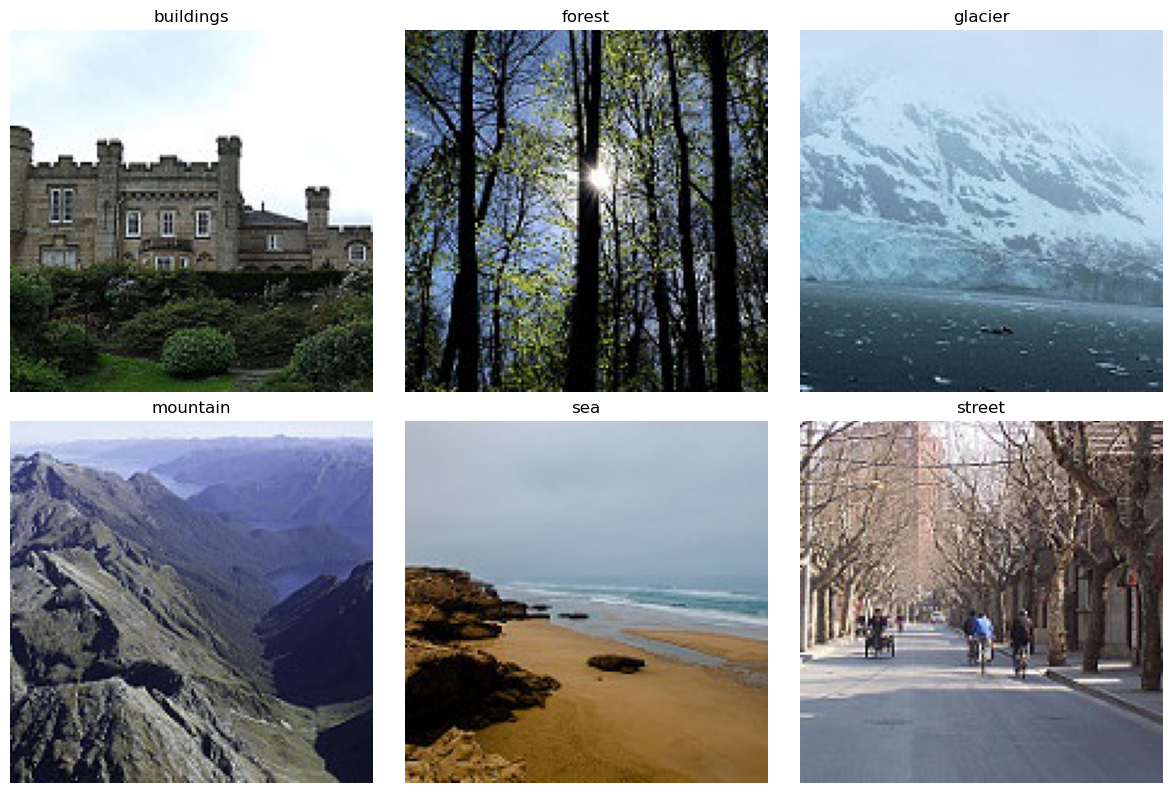

In [8]:
plt.figure(figsize=(12,8))
for i,class_name in enumerate(classes):
    class_path = os.path.join(train_dir, class_name)
    images=os.listdir(class_path)
    image_name = random.choice(images)
    image_path = os.path.join(class_path, image_name)
    img = Image.open(image_path)
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')
plt.tight_layout()
plt.show()
        

## 6. Data Preprocessing

Data preprocessing is an important step in image classification. It involves preparing raw images in a suitable format before providing them to the Convolutional Neural Network (CNN).

In this project, the images are preprocessed to ensure consistency and improve model performance.

The following preprocessing techniques are performed:

### 6.1 Image Resizing

Images in the dataset may have different dimensions. Therefore, all images are resized to a fixed dimension of **150 × 150 pixels**.

This ensures that all images have the same input size when passed to the CNN model.

### 6.2 Image Normalization

Image pixels generally have values ranging from 0 to 255. Normalization scales these values to a range between 0 and 1 by dividing each pixel value by 255.

This helps the model process image data more efficiently during training.

### 6.3 Train and Validation Split

The training dataset is divided into two parts:

- **Training Set:** Used to train the CNN model.
- **Validation Set:** Used to evaluate the model during training and monitor its performance on unseen data.

The provided testing dataset is kept separate and will be used for final model evaluation.

### 6.4 Data Augmentation

Data augmentation is used to increase the variety of training images by applying transformations such as rotation, horizontal flipping, and zooming.

It helps the CNN model learn different variations of images and reduces overfitting.

**Note:** Data augmentation is applied only to the training dataset, not to the validation or testing datasets.

Original image size: (150, 150)
Resized image size: (150, 150)


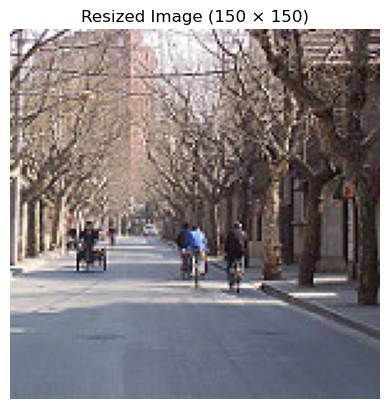

In [9]:
img = Image.open(image_path)

resized_img = img.resize((150, 150))

print("Original image size:", img.size)
print("Resized image size:", resized_img.size)
plt.imshow(resized_img)
plt.title("Resized Image (150 × 150)")
plt.axis('off')
plt.show()

In [10]:
train_images=[]
train_labels=[]
for class_name in classes:
    class_path = os.path.join(train_dir, class_name)
    images=os.listdir(class_path)
    for image_name in images:
        image_path=os.path.join(class_path,image_name)
        img = Image.open(image_path).convert('RGB')
        resized_img = img.resize((150, 150))
        img_array = np.array(resized_img)
        train_images.append(img_array)
        train_labels.append(class_name)

In [11]:
print("Total training images:", len(train_images))
print("Total training labels:", len(train_labels))
print("Image shape:", train_images[0].shape)

Total training images: 14034
Total training labels: 14034
Image shape: (150, 150, 3)


In [46]:
X_train = np.array(train_images)
print("Training data shape:", X_train.shape)
X_train = X_train / 255.0
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data shape: (14034, 150, 150, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train,X_val,y_train,y_val=train_test_split(
    X_train,
    train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

In [49]:
print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

print("Training labels:", len(y_train))
print("Validation labels:", len(y_val))

Training images: (11227, 150, 150, 3)
Validation images: (2807, 150, 150, 3)
Training labels: 11227
Validation labels: 2807


In [50]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [51]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [52]:
train_datagen=ImageDataGenerator(rotation_range=20,
                                 horizontal_flip=True,
                                 zoom_range=0.2,
                                 width_shift_range=0.1,
                                 height_shift_range=0.1)

In [53]:

print("Shape before adding batch dimension",X_train.shape)
batch_dimension=np.expand_dims(X_train[0],axis=0)
print("Shape after adding batch dimension",batch_dimension.shape)

Shape before adding batch dimension (11227, 150, 150, 3)
Shape after adding batch dimension (1, 150, 150, 3)


In [54]:
augmented_images = []

for i in range(5):
    augmented_batch = next(train_datagen.flow(batch_dimension, batch_size=1))
    augmented_images.append(augmented_batch[0])

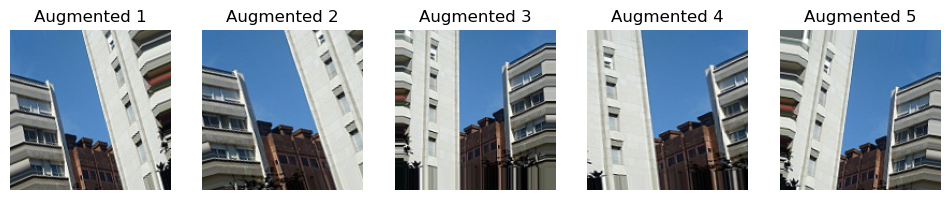

In [55]:
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(augmented_images[i])
    plt.axis('off')
    plt.title(f"Augmented {i+1}")

plt.show()

In [56]:
print("Number of augmented images:", len(augmented_images))
print("Shape of augmented image:", augmented_images[0].shape)

Number of augmented images: 5
Shape of augmented image: (150, 150, 3)


## 6.5 Label Encoding

### Introduction

Label Encoding is a data preprocessing technique used to convert categorical text labels into numerical values.

In our Intel Image Classification dataset, the six image categories are represented as text labels:

- buildings
- forest
- glacier
- mountain
- sea
- street

Since machine learning models work with numerical data, we convert these text labels into numbers.

### Why is Label Encoding Required?

- Converts text-based class labels into numerical values.
- Makes labels suitable for CNN model training.
- Helps the model distinguish between different image categories.

### Class Mapping

The six categories are converted into numerical labels:

| Image Category | Encoded Value |
|---|---:|
| buildings | 0 |
| forest | 1 |
| glacier | 2 |
| mountain | 3 |
| sea | 4 |
| street | 5 |

### Implementation

The `LabelEncoder` class from Scikit-learn is used to convert the training and validation labels into numerical values.

The same encoder is used for both datasets to maintain consistent class mapping.

In [57]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

label_encoder.fit(train_labels)

y_train_encoded = label_encoder.transform(y_train)
y_val_encoded = label_encoder.transform(y_val)


In [58]:
print("Class mapping:", label_encoder.classes_)
print("Encoded training labels:", y_train_encoded[:10])
print("Encoded validation labels:", y_val_encoded[:10])

Class mapping: ['buildings' 'forest' 'glacier' 'mountain' 'sea' 'street']
Encoded training labels: [0 4 2 2 1 5 3 3 4 2]
Encoded validation labels: [1 2 3 0 0 3 4 4 4 5]


# 7. Building a Convolutional Neural Network (CNN) from Scratch

## 7.1 Introduction to Convolutional Neural Networks (CNN)

A Convolutional Neural Network (CNN) is a type of deep learning model mainly used for image processing and image classification.

CNN automatically learns important features from images, such as edges, shapes, patterns, textures and objects.

In our Intel Image Classification project, CNN is used to classify images into six categories: buildings, forest, glacier, mountain, sea and street.

### How does CNN work?

A CNN generally works through the following stages:

1. **Input Layer:** Receives the input image.
2. **Convolution Layer:** Extracts important features using filters.
3. **ReLU Activation:** Introduces non-linearity.
4. **Pooling Layer:** Reduces the spatial dimensions of feature maps.
5. **Flatten Layer:** Converts feature maps into a one-dimensional vector.
6. **Dense Layer:** Learns relationships between extracted features.
7. **Output Layer:** Predicts the image category using Softmax activation.

---

## 7.2 Convolution Layer

### What is Convolution?

Convolution is an operation in which a small matrix called a filter or kernel slides over an input image to detect specific features.

For example:
- Edges and lines.
- Shapes and curves.
- Textures and patterns.

### How does Convolution work?

1. The filter is placed over a small region of the input image.
2. Corresponding values are multiplied.
3. The multiplication results are added.
4. The filter moves to the next position.
5. This process continues to generate a feature map.

### Important Terms

| Term | Meaning |
|---|---|
| Input Image | Original image given to CNN |
| Filter/Kernel | Small matrix used to detect features |
| Stride | Number of pixels the filter moves |
| Feature Map | Output produced after convolution |

---

## 7.3 Filters (Kernels)

A kernel is a small matrix of weights that slides over an input image to detect specific features.

Example of a 3 × 3 kernel:

\[
\begin{bmatrix}
1 & 0 & -1\\
1 & 0 & -1\\
1 & 0 & -1
\end{bmatrix}
\]

This is an example of a filter that can respond to vertical edges.

### Multiple Filters

A convolutional layer can contain multiple filters.

For example:
- One filter may detect vertical edges.
- Another filter may detect horizontal edges.
- Another filter may detect diagonal patterns.
- Other filters may learn more complex features during training.

Each filter produces one feature map.

**Note:** In CNN, filter weights are generally learned automatically during training through backpropagation.

---

## 7.4 ReLU Activation Function

### What is ReLU?

ReLU stands for Rectified Linear Unit.

It is an activation function used in CNN to introduce non-linearity into the network.

It replaces all negative input values with zero and keeps positive values unchanged.

### Mathematical Representation

\[
f(x)=\max(0,x)
\]

### Example

| Input (x) | ReLU Output |
|---:|---:|
| -5 | 0 |
| -2 | 0 |
| 0 | 0 |
| 3 | 3 |
| 7 | 7 |

### Why is ReLU Used?

- Introduces non-linearity.
- Helps the network learn complex patterns.
- Computationally simple.
- Helps reduce the vanishing gradient problem compared with sigmoid or tanh in many settings.

---

## 7.5 Pooling Layer

### What is Pooling?

Pooling is a down-sampling operation used in CNN to reduce the spatial dimensions (height and width) of feature maps.

### Why is Pooling Used?

- Reduces computational complexity.
- Reduces the size of feature maps.
- Retains important features.
- Improves robustness to small changes in image position.

### Types of Pooling

#### A. Max Pooling

Max Pooling selects the maximum value from a given region.

Example:

\[
\begin{bmatrix}
1 & 3\\
2 & 4
\end{bmatrix}
\]

Output:

\[
4
\]

#### B. Average Pooling

Average Pooling calculates the average of all values in a given region.

\[
\frac{1+3+2+4}{4}=2.5
\]

Output:

\[
2.5
\]

### Difference Between Max Pooling and Average Pooling

| Max Pooling | Average Pooling |
|---|---|
| Selects the maximum value | Calculates the average value |
| Retains strongest activations | Retains average information |
| Commonly used in CNN architectures | Also used in CNN architectures |

---

## 7.6 Down-sampling

Down-sampling means reducing the height and width of a feature map while retaining important information.

For example:

If the input feature map is:

\[
4 \times 4
\]

After applying 2 × 2 Max Pooling with stride 2:

\[
2 \times 2
\]

The spatial dimensions are reduced.

Similarly, a feature map of size 150 × 150 becomes 75 × 75 after applying 2 × 2 Max Pooling with stride 2.

---

## 7.7 Flatten Layer

### What is Flatten?

Flatten is a layer that converts multidimensional feature maps into a one-dimensional vector.

CNN convolution and pooling layers extract features in 2D feature maps. Before passing these features to fully connected (Dense) layers, we flatten them.

### Example

Suppose the input to the Flatten layer is:

\[
2 \times 2 \times 3
\]

The total number of values is:

\[
2 \times 2 \times 3=12
\]

After flattening, the output becomes a one-dimensional vector containing 12 values.

### Why is Flatten Used?

- Converts feature maps into a one-dimensional vector.
- Makes extracted features suitable for Dense layers.
- Connects convolutional feature extraction with classification.

---

## 7.8 Dense Layer (Fully Connected Layer)

### What is a Dense Layer?

A Dense layer is a fully connected neural network layer in which every neuron is connected to all neurons in the previous layer.

It learns relationships between the features extracted by convolutional and pooling layers.

### Why is Dense Layer Used?

- Combines the extracted features.
- Learns complex relationships.
- Helps classify images into different categories.

In our Intel Image Classification project, the Dense layer uses the extracted features to distinguish between buildings, forest, glacier, mountain, sea and street.

---

## 7.9 Dropout Layer

### What is Dropout?

Dropout is a regularization technique used to reduce overfitting in neural networks.

During training, it randomly deactivates a fraction of neurons.

For example, if dropout is set to 0.5, approximately 50% of the relevant neurons are temporarily deactivated during each training step.

### Why is Dropout Used?

- Reduces overfitting.
- Prevents excessive dependence on particular neurons.
- Helps improve generalization.

**Note:** Dropout is active during training and inactive during testing and normal inference.

---

## 7.10 Output Layer – Softmax Activation

### What is Softmax?

Softmax is an activation function used in the output layer for multi-class classification.

It converts the model's output scores into probabilities between 0 and 1, with all probabilities adding up to 1.

### Example

Suppose our CNN predicts the following probabilities:

| Class | Probability |
|---|---:|
| Buildings | 0.05 |
| Forest | 0.75 |
| Glacier | 0.03 |
| Mountain | 0.10 |
| Sea | 0.04 |
| Street | 0.03 |

The highest probability is 0.75.

Therefore, the predicted class is **Forest**.

### Why is Softmax Used?

- Converts output scores into probabilities.
- Helps identify the most likely class.
- Suitable for multi-class classification problems.

Since our dataset contains six categories, the final output layer contains six neurons.

---

## 7.11 Complete CNN Architecture

Our CNN architecture follows this structure:

| Layer | Purpose |
|---|---|
| Input Layer | Receives 150 × 150 RGB images |
| Conv2D (32 filters) | Extracts basic features |
| ReLU | Introduces non-linearity |
| MaxPooling2D | Reduces spatial dimensions |
| Conv2D (64 filters) | Extracts more complex features |
| ReLU | Introduces non-linearity |
| MaxPooling2D | Reduces dimensions |
| Conv2D (128 filters) | Extracts higher-level features |
| ReLU | Introduces non-linearity |
| MaxPooling2D | Reduces dimensions |
| Flatten | Converts feature maps into a vector |
| Dense (128 neurons) | Learns feature relationships |
| Dropout (0.5) | Reduces overfitting |
| Dense (6 neurons) | Predicts six image classes |
| Softmax | Produces class probabilities |

---

## 7.12 Important CNN Training Parameters

Before training the CNN model, it is important to understand three essential training parameters: Epoch, Batch Size and Learning Rate.

### 1. Epoch

An epoch is one complete pass of the entire training dataset through the neural network.

For example, if the training dataset contains 11,227 images:

- 1 Epoch means the model processes all 11,227 training images once.
- 10 Epochs means the model processes the entire training dataset 10 times.

**Purpose:** Multiple epochs allow the model to learn patterns and improve its predictions.

### 2. Batch Size

Batch size refers to the number of training images processed together before updating the model's weights.

For example, if the batch size is 32:

- The model processes 32 images at a time.
- It calculates the prediction error.
- It updates the weights.
- This process continues until all training images are processed.

Common batch sizes are 16, 32 and 64.

### 3. Learning Rate

Learning rate is a hyperparameter that controls how much the model's weights are updated during training.

- A high learning rate may cause the model to miss the optimal solution.
- A very low learning rate may make training slow.
- A suitable learning rate helps the model learn efficiently.

For example, a commonly used initial learning rate is 0.001.

### Difference Between Epoch, Batch Size and Learning Rate

| Parameter | Meaning |
|---|---|
| Epoch | Number of complete passes through the training dataset |
| Batch Size | Number of images processed before a weight update |
| Learning Rate | Controls the size of weight updates |

### Conclusion

Epoch, batch size and learning rate are important hyperparameters that influence the training speed and performance of a CNN model.

In [59]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [60]:
model = Sequential()

model.add(tf.keras.Input(shape=(150, 150, 3)))

In [61]:
model.add(Conv2D(32, (3, 3), activation='relu'))

In [62]:
model.add(MaxPooling2D(pool_size=(2, 2)))

In [63]:
model.add(Conv2D(64, (3, 3), activation='relu'))

In [64]:
model.add(MaxPooling2D(pool_size=(2, 2)))

In [65]:
model.add(Conv2D(128, (3, 3), activation='relu'))

In [66]:
model.add(MaxPooling2D(pool_size=(2, 2)))

In [67]:
model.add(Flatten())

In [68]:
model.add(Dense(128, activation='relu'))

In [69]:
model.add(Dropout(0.5))

In [70]:
model.add(Dense(6, activation='softmax'))

In [71]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [73]:
X_train = X_train.astype('float32')
X_val = X_val.astype('float32')

print("Training data type:", X_train.dtype)
print("Validation data type:", X_val.dtype)

Training data type: float32
Validation data type: float32


In [74]:
train_generator = train_datagen.flow(
    X_train,
    y_train_encoded,
    batch_size=32,
    shuffle=True
)

In [75]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [76]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [77]:
model_checkpoint = ModelCheckpoint(
    filepath='../models/best_cnn_model.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

In [78]:
callbacks = [early_stopping, model_checkpoint]

In [79]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=(X_val, y_val_encoded),
    callbacks=callbacks
)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 454s 1s/step - accuracy: 0.5172 - loss: 1.2043 - val_accuracy: 0.6673 - val_loss: 0.8941
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 519s 1s/step - accuracy: 0.6380 - loss: 0.9665 - val_accuracy: 0.7260 - val_loss: 0.7434
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 536s 2s/step - accuracy: 0.6953 - loss: 0.8317 - val_accuracy: 0.7538 - val_loss: 0.6807
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 4117s 12s/step - accuracy: 0.7251 - loss: 0.7680 - val_accuracy: 0.7649 - val_loss: 0.6429
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 1933s 6s/step - accuracy: 0.7456 - loss: 0.7034 - val_accuracy: 0.8005 - val_loss: 0.5875
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 16676s 48s/step - accuracy: 0.7619 - loss: 0.6711 - val_accuracy: 0.7852 - val_loss: 0.6389
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 2043s 6s/step - accuracy: 0.7745 - loss: 0.6399 - val_accuracy: 0.8169 - val_loss: 0.5425
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 704s 2s/step - accuracy: 0.7847 - loss: 0.6067 - v

In [80]:
print("Epochs completed:", len(history.history['loss']))
print("Best validation loss:", min(history.history['val_loss']))

Epochs completed: 13
Best validation loss: 0.47492605447769165


 ### Visualizing Training and Validation Performance

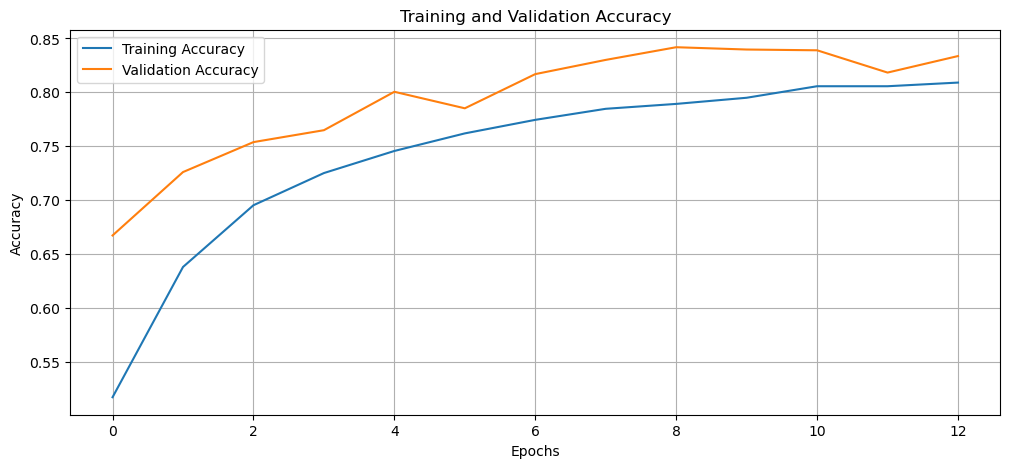

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

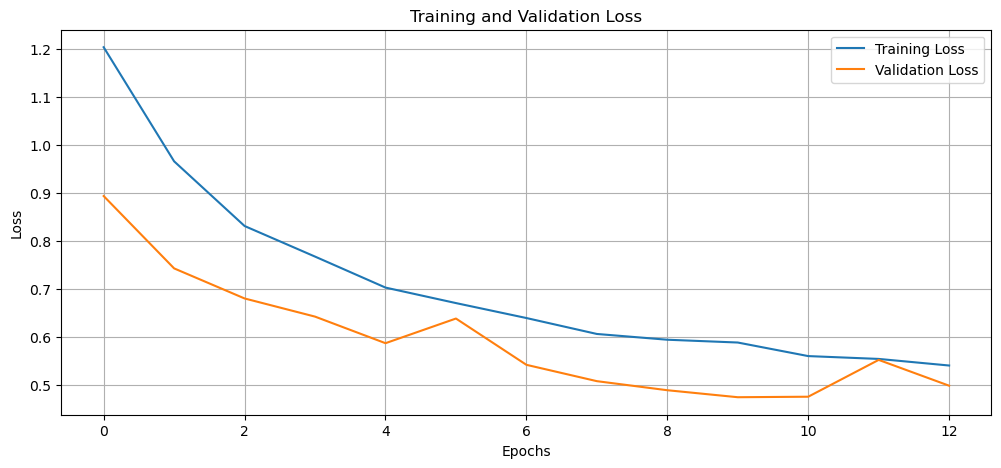

In [82]:
plt.figure(figsize=(12, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

### Loading Test Dataset

In [83]:
test_images = []
test_labels = []

for class_name in label_encoder.classes_:
    class_path = os.path.join(test_dir, class_name)

    for image_name in os.listdir(class_path):
        image_path = os.path.join(class_path, image_name)

        try:
            img = Image.open(image_path).convert('RGB')
            img = img.resize((150, 150))

            test_images.append(np.array(img))
            test_labels.append(class_name)

        except Exception as e:
            print("Error loading:", image_path, e)

In [84]:
X_test = np.array(test_images)
X_test = X_test.astype('float32') / 255.0

print("Test data shape:", X_test.shape)
print("Minimum pixel value:", X_test.min())
print("Maximum pixel value:", X_test.max())

Test data shape: (3000, 150, 150, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [85]:
y_test_encoded = label_encoder.transform(test_labels)

print("Test labels:", len(y_test_encoded))
print("Encoded labels:", y_test_encoded[:10])

Test labels: 3000
Encoded labels: [0 0 0 0 0 0 0 0 0 0]


### Evaluating CNN Model on Test Data

In [86]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 34s 359ms/step - accuracy: 0.8417 - loss: 0.4645
Test Loss: 0.46452873945236206
Test Accuracy: 84.16666388511658 %


### Classification Report and Confusion Matrix

In [87]:
y_pred_prob = model.predict(X_test)

y_pred_encoded = np.argmax(y_pred_prob, axis=1)

print("Predictions shape:", y_pred_encoded.shape)
print("Actual labels shape:", y_test_encoded.shape)

94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 373ms/step
Predictions shape: (3000,)
Actual labels shape: (3000,)


In [88]:
from sklearn.metrics import classification_report

In [89]:
print(classification_report(
    y_test_encoded,
    y_pred_encoded,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

   buildings       0.81      0.86      0.83       437
      forest       0.94      0.98      0.96       474
     glacier       0.83      0.78      0.80       553
    mountain       0.81      0.73      0.77       525
         sea       0.78      0.89      0.83       510
      street       0.88      0.84      0.86       501

    accuracy                           0.84      3000
   macro avg       0.84      0.85      0.84      3000
weighted avg       0.84      0.84      0.84      3000



## Confusion Matrix

A confusion matrix is used to evaluate the performance of a classification model.

It compares the actual class labels with the predicted class labels.

- Diagonal values represent correctly classified images.
- Off-diagonal values represent incorrectly classified images.

It helps identify which classes are commonly confused by the model.

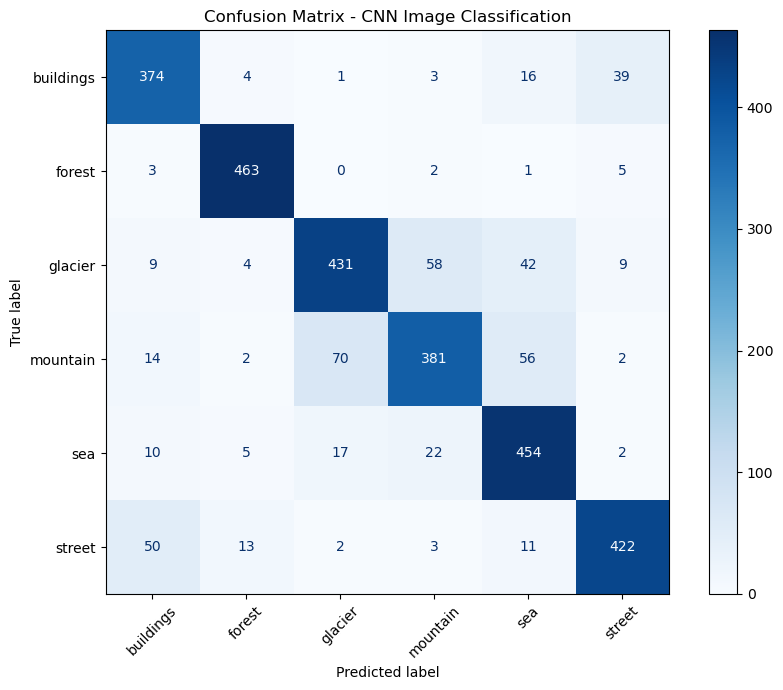

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_encoded, y_pred_encoded)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation=45,
    values_format='d'
)

plt.title('Confusion Matrix - CNN Image Classification')
plt.tight_layout()
plt.show()

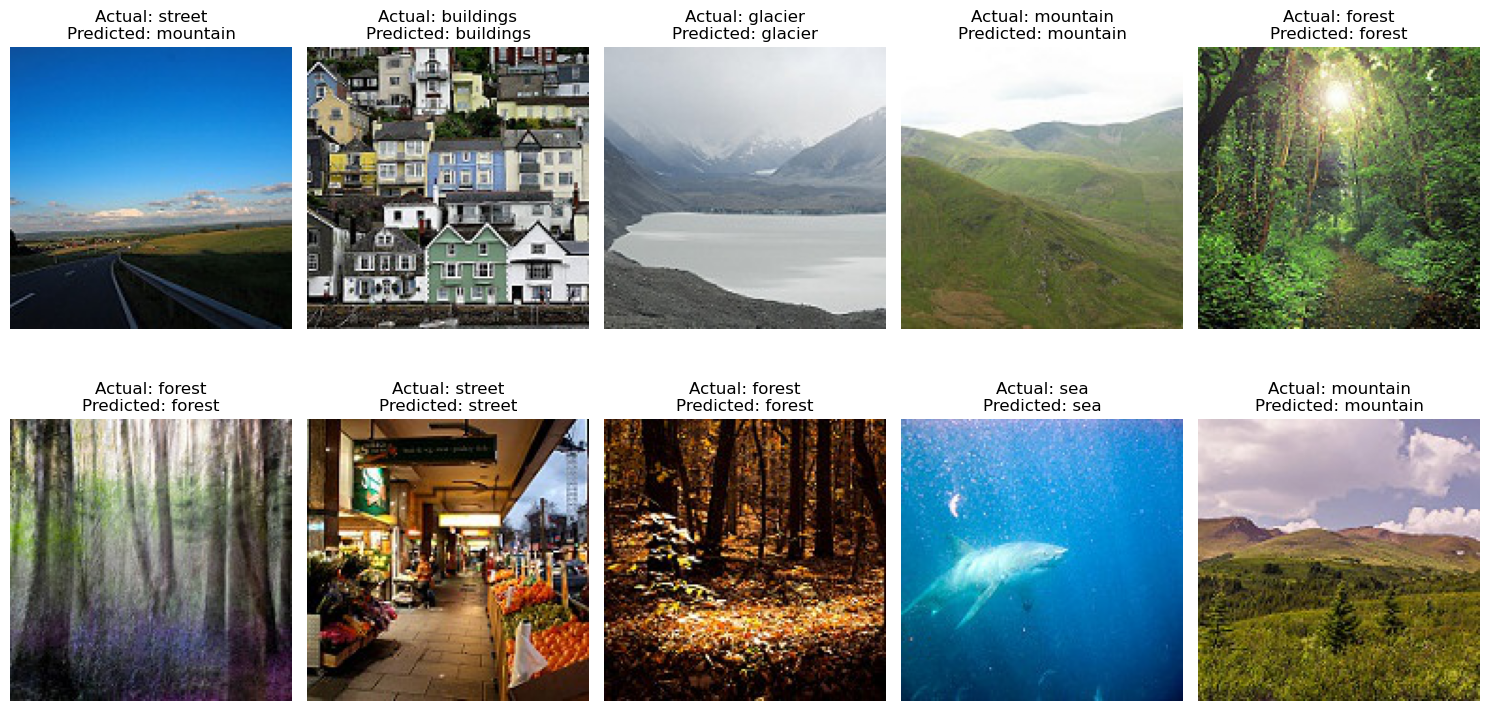

In [91]:
import random

indices = random.sample(range(len(X_test)), 10)

plt.figure(figsize=(15, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    actual = label_encoder.inverse_transform([y_test_encoded[idx]])[0]
    predicted = label_encoder.inverse_transform([y_pred_encoded[idx]])[0]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()

##  Saving the Trained CNN Model

The trained CNN model is saved in Keras format for future use.

This allows us to load the model later without training it again.

In [92]:
import os

model_path = '../models/best_cnn_model.keras'

print("Model exists:", os.path.exists(model_path))

Model exists: True


##  Loading the Saved CNN Model

The saved model can be loaded whenever we need to make predictions on new images.

We use the Keras load_model() function.

In [93]:
from tensorflow.keras.models import load_model

loaded_model = load_model('../models/best_cnn_model.keras')

print("Model loaded successfully!")

Model loaded successfully!
